> **第二部分的历史方法记录｜归档说明（2026-10-28）**
> 本文保留当时的方法、代码与输出；“尚未拟合”等进度句只描述该阶段。最新结果见 [H0–H3 综合 Notebook](matching_h0_h3_results.ipynb) 与 [当前 README](README_zh.md)。第三部分尚未正式分析。
> 研究日志不是一键复现入口；尤其 observation_recovery 含昂贵采样和本地中间文件依赖，不要直接 Run All。

# Matching 竞争机制：独立核查、参数敏感性与识别限制

范围：审查首轮 H0–H3 前向模拟，检查观察机制和结构识别，并开展固定范围的敏感性分析。不是新的 MCMC、参数恢复或模型恢复。保留首轮 Notebook 和既有科学输出；本 Notebook 不写入这些文件。

使用公开原始数据、42 名被试名单及历史 M4 参数摘要。随机种子仅用于被试 bootstrap；参数网格的预测由联合选择–RT 密度积分计算，保留截止后的超时质量，不依赖少量模拟重复。固定网格不是推断先验或拟合程序。对历史数据的探索不能当作预注册验证。

文献核查：Hu et al. (2020) 将原始 Matching 结果联系到信息摄取速率；其模型与新 H0–H3 不同。Pan et al. (2025) 提供 dockerHDDM 计算和诊断流程，并指出恢复应结合样本与试次数评价。邬思宇等（2026，预印本）第 3.3–3.4 节定义选择编码下 μ = ±v + dc；这一编码规则不自动保证本研究含关系难度的参数可识别。


## 主要发现

本轮完成输入逐行核对、实验观察规则核查、参数映射的结构检查、1,296 个固定参数组合的联合预测检查，以及历史被试参数均值代入检查。没有估计新模型或重跑旧 MCMC。

1. **编码一致。** 24,527 条合法反应与现有输入逐行一致；649 条无反应与24条其他无效响应分开处理。截止代理在被试内稳定，未发现合法响应越过代理值 1 ms。
2. **难度参照影响 dc 的解释。** 自由关系中心存在精确等预测方向；零和 log 难度约束将其固定。下文给出 H1 到非零 dc 对比 H3 的等预测例子。这个问题不能靠增加样本量解决，但不意味着约束下参数一定不能恢复。
3. **历史参数不是新观察模型的校准结果。** 群体 t 均值下有 741 条合法 RT 不在纯 DDM 的支持范围内；按历史被试 t 均值也有 410 条。历史混合模型含离群成分，不能把删去该成分后的代入结果直接当作其 PPC。
4. **本轮网格没有同时解释七个关键指标。** 两个 H3 点落入 RT 差异、正确率差异和 Self 超时率五项区间，却预测 Self 平均正确 RT 仅 525–526 ms（观测 709 ms），快速条件选择差异也明显不足。有限网格不构成对全部 DDM 参数空间的排除。
5. **小幅截止调整不足以消除失配。** 在群体参数代入的同一 Self 口径下，截止延后 16.7 ms 后超时预测由 6.51% 降为 6.01%，观测为 2.33%；历史被试参数均值代入为 6.79%。这些均为固定参数诊断，不是后验预测。

目前没有参数恢复或模型恢复的结果，不能宣称 H1/H2/H3 可被可靠区分，也不能选择真实数据的获胜机制。旧 HDDM 入口不实现本方案的关系难度和截止生存概率；直接拿它拟合删失模拟数据不是相应模型的恢复验证。下一阶段应先固定一致的生成—估计模型及其心理学解释，再实施层级恢复。


In [1]:
from pathlib import Path
import hashlib, json, platform, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import cumulative_trapezoid
from scipy.special import expit, logit
import hddm
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / 'Data/matching_input.csv').exists():
    ROOT = ROOT / '02_reanalysis_2026'
assert (ROOT / 'Data/matching_input.csv').exists(), 'Run from repository root or Part II'
REPO = ROOT.parent
paths = {
 'raw': REPO/'01_reproduction_2020/Data/raw/confirm/MS_rep_matchingTask_raw.csv',
 'subjects': REPO/'01_reproduction_2020/Output/behavior/confirm/MS_match_behav_wide.csv',
 'parameters': ROOT/'Output/hddm/matching/m4/final/diagnostics/matching_parameter_contrasts.csv',
 'diagnostics': ROOT/'Output/hddm/matching/m4/final/diagnostics/matching_precise_diagnostics.csv'}
hashes = {k:hashlib.sha256(p.read_bytes()).hexdigest() for k,p in paths.items()}
print(json.dumps({'sources':hashes,'python':platform.python_version(),'hddm':hddm.__version__,
                  'numpy':np.__version__,'pandas':pd.__version__,'seed':2026102401},indent=2))
raw = pd.read_csv(paths['raw'],keep_default_na=False)
subjects = sorted(pd.read_csv(paths['subjects']).Subject.unique())
d = raw[raw.Subject.isin(subjects)].copy().reset_index(drop=True)
assert len(subjects)==42 and len(d)==25200 and d.groupby('Subject').size().eq(600).all()
d['condition'] = d.Morality+'_'+d.Identity
d['stim'] = (d.Match=='match').astype(int)
mapping={'moralSelf':('Good','Self'),'immoralSelf':('Bad','Self'),
         'moralOther':('Good','Other'),'immoralOther':('Bad','Other')}
def relation(row):
    x,y=mapping[row.Shape],mapping[row.Label]
    return 'same' if x==y else ('identity_only' if x[0]==y[0] else ('valence_only' if x[1]==y[1] else 'both'))
d['relation']=d.apply(relation,axis=1)
assert ((d.relation=='same')==d.stim.eq(1)).all()
deadlines=d[d.ACC.eq(-1)].groupby('Subject').RT.median()
assert len(deadlines)==42
p=pd.read_csv(paths['parameters']).set_index('parameter')['mean']
diag=pd.read_csv(paths['diagnostics'],index_col=0)
A,T,Z=float(diag.loc['a','mean']),float(diag.loc['t','mean']),float(p['z'])
V0=np.sqrt(p['v(Self.Good)']*p['v(Self.Bad)'])
D0=(p['dc(Self.Good)']+p['dc(Self.Bad)'])/2
BV=np.log(p['v(Self.Good)']/p['v(Self.Bad)'])
BD=p['dc(Self.Good)']-p['dc(Self.Bad)']
MODELS=['H0','H1','H2','H3']; SCENARIOS=['S0','S1','S2','S3']; REPEATS=20
conditions=['Good_Self','Bad_Self','Good_Other','Bad_Other']
effects=pd.DataFrame([[m, BV if m in ['H1','H3'] else 0,BD if m in ['H2','H3'] else 0] for m in MODELS],columns=['model','beta_log_v','beta_dc'])
display(effects)
print('a,t,z:',A,T,Z,'deadline proxy range:',deadlines.min(),deadlines.max())


{
  "sources": {
    "raw": "ee0da77b217f5f4719e41efa7adae207b1f1deacd87ee86acb1bd50ff528afbc",
    "subjects": "2ad1d92d3828f474efd78956068320d49705b9a2bc84f51a5823cec20042e1d8",
    "parameters": "81e468b380e44af75809fbc901c24a818ed7c929b4bf23ce72e1707a48e5796a",
    "diagnostics": "af5a5eed9f17cb5a4bbdcf8ecfd4a032266d879209e0622d8f1e4c23f0541025"
  },
  "python": "3.9.13",
  "hddm": "1.0.1RC",
  "numpy": "1.23.3",
  "pandas": "2.0.1",
  "seed": 2026102401
}


,model,beta_log_v,beta_dc
0,H0,0.000000,0.000000
1,H1,0.358023,0.000000
2,H2,0.000000,0.600222
3,H3,0.358023,0.600222


a,t,z: 1.2242069382093794 0.464327964026853 0.5680916892738427 deadline proxy range: 1.017 1.1831


## 1. 编码、观察窗口与数据支持

根据实际按键和正确按键独立解码上边界选择，与当前输入表逐行比较。截止代理按被试计算，同时检查 Block/Bin 变化和合法反应越界。历史群体均值 t 不是所有被试或每次试验的最短 RT；检查把它直接代入纯 DDM 后产生的零密度问题。


In [2]:
valid=d.Resp.isin(['m','n'])&d.ACC.isin([0,1])&d.RT.gt(0)
choice=np.where(d.stim.eq(1),d.Resp.eq(d.CorrResp),d.Resp.ne(d.CorrResp)).astype(int)
inp=pd.read_csv(ROOT/'Data/matching_input.csv')
assert np.array_equal(d.loc[valid,'Subject'],inp.subj_idx)
assert np.array_equal(choice[valid],inp.response)
assert np.array_equal(d.loc[valid,'stim'],inp.stim)
assert np.allclose(d.loc[valid,'RT'],inp.rt,atol=1e-12)
assert np.array_equal((choice[valid]==d.loc[valid,'stim']).astype(int),d.loc[valid,'ACC'])
print('All 24,527 valid rows agree with saved input: subject, response, stimulus, RT, accuracy.')
display(d.groupby(['ACC','Resp']).size().rename('n').to_frame())
D=d.Subject.map(deadlines)
noresp=d[d.ACC.eq(-1)]
spread=noresp.groupby('Subject').RT.agg(['min','max','median','size'])
block_spread=noresp.groupby(['Subject','Block','Bin']).RT.median().groupby('Subject').agg(lambda x:x.max()-x.min())
print('Maximum within-subject omission RT spread (ms):',1000*(spread['max']-spread['min']).max())
print('Maximum block/bin median spread (ms):',1000*block_spread.max())
print('Valid responses beyond proxy + 1 ms:',int((valid&(d.RT>D+.001)).sum()))
print('Maximum valid RT minus proxy (ms):',1000*(d.loc[valid,'RT']-D[valid]).max())
display(pd.DataFrame({'threshold':[.1,.2,.3,.38,T],
 'valid_RT_at_or_below':[int((valid&d.RT.le(x)).sum()) for x in [.1,.2,.3,.38,T]]}))
subject_t={s:float(diag.loc['t_subj.'+str(s),'mean']) for s in subjects}
below_subject=valid & (d.RT<=d.Subject.map(subject_t))
print('Valid RT below historical subject t mean:',below_subject.sum(), 'fraction:',below_subject.sum()/valid.sum())
print('Observed timeout rate (all 25,200 trials):',d.ACC.eq(-1).mean())
# Verify the sign symmetry of the installed Wiener density.
test_rt=np.array([.55,.7,1.0])
f1=hddm.wfpt.pdf_array(test_rt,1.5,0.,A,Z,0.,.3,0.,err=1e-8)
f2=hddm.wfpt.pdf_array(-test_rt,-1.5,0.,A,1-Z,0.,.3,0.,err=1e-8)
assert np.allclose(f1,f2,rtol=1e-9,atol=1e-10)
import inspect
from hddm.models.hddm_stimcoding import KnodeWfptStimCoding
print(inspect.getsource(KnodeWfptStimCoding.create_node))


All 24,527 valid rows agree with saved input: subject, response, stimulus, RT, accuracy.


n
ACC Resp        
-1  NA       649
 0  k          1
    m       1971
    n       1903
 1  m      10363
    n      10290
 2  ,<         3
    h          6
    j          3
    space      2
    u          6
    y          3

Maximum within-subject omission RT spread (ms): 0.39999999999995595
Maximum block/bin median spread (ms): 0.09999999999998899
Valid responses beyond proxy + 1 ms: 0
Maximum valid RT minus proxy (ms): -0.29999999999996696


,threshold,valid_RT_at_or_below
0,0.100000,0
1,0.200000,28
2,0.300000,62
3,0.380000,168
4,0.464328,741


Valid RT below historical subject t mean: 410 fraction: 0.016716271863660457
Observed timeout rate (all 25,200 trials): 0.025753968253968255
    def create_node(self, name, kwargs, data):
        # AF-COMMENT: Not fully clear how creat_node works !
        # StimCoding more transparent via regressor ?

        # the addition of "depends=['stim']" in the call of
        # KnodeWfptInvZ in HDDMStimCoding makes that data are
        # submitted splitted by the values of the variable stim the
        # following lines check if the variable stim is equal to the
        # value of stim for which z' = 1-z and transforms z if this is
        # the case (similar to v)
        dc = kwargs.pop("dc", None)
        if all(
            data[self.stim_col] == self.stims[0]
        ):  # AF-COMMENT: Should this be reversed? -> self.stims[1]
            if self.split_param == "z":
                kwargs["z"] = 1 - kwargs["z"]
            elif self.split_param == "v" and dc is None:
                kwar

## 2. 结构可识别性：关系难度的参照约束

若 Match 和 Mismatch 的漂移幅度相同，μ₊ = v + dc、μ₋ = −v + dc，可代数反解 v = (μ₊−μ₋)/2、dc = (μ₊+μ₋)/2。这只说明在有效漂移已知、模型假设成立时的参数映射。

加入 Mismatch 难度倍率 r_j 后，μ₋ⱼ = −v r_j + dc。若允许关系难度的整体水平自由变化，则对满足正值约束的 k，下列变换严格保持所有有效漂移：

```math
v'_c=(1-k)v_c,\qquad dc'_c=dc_c+k v_c,\qquad r'_j=(r_j+k)/(1-k).
```

保持 a、t、z 和截止规则不变，整个选择–RT–超时分布也不变；增加被试或试次数无法消除此等价性。零和 log 难度约束排除了这一自由度，但把 Mismatch 难度几何中心固定为 Match 的参照是一项实质假设。下面比较有、无此约束的 Jacobian 秩，并构造 H1 与 H3 的等预测例子。这不是全面证明其他全部参数都可识别。


In [3]:
from scipy.optimize._numdiff import approx_derivative
v=np.array([p['v(Self.Good)'],p['v(Self.Bad)'],p['v(Other.Good)'],p['v(Other.Bad)']])
dc=np.array([D0,D0,p['dc(Other.Good)'],p['dc(Other.Bad)']]) # H1 target contrast
lam=np.array([-.2,-.05,.25]); r=np.exp(lam)
def mapping_unconstrained(theta):
    v=np.exp(theta[:4]); dc=theta[4:8]; r=np.exp(theta[8:])
    return np.column_stack([v+dc,dc[:,None]-v[:,None]*r]).ravel()
def mapping_centered(theta):
    return mapping_unconstrained(np.r_[theta[:8],theta[8:],-sum(theta[8:])])
theta=np.r_[np.log(v),dc,lam]
J=approx_derivative(mapping_unconstrained,theta)
J0=approx_derivative(mapping_centered,theta[:-1])
k=.1; vp=(1-k)*v; dp=dc+k*v; rp=(r+k)/(1-k)
err=np.max(abs(mapping_unconstrained(theta)-mapping_unconstrained(np.r_[np.log(vp),dp,np.log(rp)])))
assert err<1e-12
rank=np.linalg.matrix_rank(J,tol=1e-7); rank0=np.linalg.matrix_rank(J0,tol=1e-7)
assert rank==10 and rank0==10
print('Free relation center: rank',rank,'of',J.shape[1],'; zero-sum center: rank',rank0,'of',J0.shape[1])
print('Maximum identical-prediction error:',err)
display(pd.DataFrame({'parameterization':['H1, centered relations','same predictions, free relation center'],
 'Good_self_minus_Bad_self_dc':[dc[0]-dc[1],dp[0]-dp[1]],
 'log_v_contrast':[np.log(v[0]/v[1]),np.log(vp[0]/vp[1])],
 'mean_log_relation':[lam.mean(),np.log(rp).mean()]}))


Free relation center: rank 10 of 11 ; zero-sum center: rank 10 of 10
Maximum identical-prediction error: 4.440892098500626e-16


,parameterization,Good_self_minus_Bad_self_dc,log_v_contrast,mean_log_relation
0,"H1, centered relations",0.000000,0.358023,0.000000
1,"same predictions, free relation center",0.066634,0.358023,0.202092


## 3. 固定网格：同时检查 RT、选择、超时和时间分布

在查看网格结果之前固定以下范围：a ∈ {1.00, 1.2242, 1.45}、t ∈ {0.30, 0.38, 0.4643} 秒、z ∈ {0.50, 0.5681, 0.65}、Self 基准 v 的倍数 ∈ {0.8, 1.0, 1.2}、β_v ∈ {0, 0.1790, 0.3580, 0.5370}、β_dc ∈ {0, 0.3001, 0.6002, 0.9003}。共 1,296 个参数组合。关系 log 难度固定为 {−0.20, −0.05, 0.25}，保留实际配对比例与各被试截止代理值。

这里使用共同生成参数，目的是隔离参数变化；不是层级拟合。范围覆盖历史锚点附近及更快的非决策过程，不能被称作全部合理参数空间。没有按结果调节网格，也没有拟合一个加权总损失。预测以数值积分计算；CBF 的每个被试、条件分箱依据模型自身的已响应 RT 分布。

参照区间为 42 名被试的配对 bootstrap 95% 区间，保持每人各条件一起重抽，种子 2026102403、4,000 次。它们是描述性、逐指标区间，没有多重校正；同时落入区间不是正式模型通过标准。


In [4]:
from itertools import product
rels=['identity_only','valence_only','both']
weights=np.empty((42,2,3))
for i,sub in enumerate(subjects):
    for ci,cond in enumerate(['Good_Self','Bad_Self']):
        counts=d[(d.Subject==sub)&d.condition.eq(cond)&d.stim.eq(0)].relation.value_counts()
        weights[i,ci]=[counts.get(r,0)/75 for r in rels]
assert np.allclose(weights.sum(axis=2),1)
dead=deadlines.reindex(subjects).to_numpy()

# Observer statistics use the same denominators and three-bin definition as the forward notebook.
def observed_subject_stats(data):
    values=[]
    for sub in subjects:
        q=data[data.Subject==sub]; stats={}
        for ci,cond in enumerate(['Good_Self','Bad_Self']):
            cc=q[q.condition.eq(cond)]; legal=valid[cc.index]
            ss=cc[legal]; edges=pd.qcut(ss.RT,3,labels=False,duplicates='drop')
            B=[]
            for b in range(3):
                ii=ss.index[np.asarray(edges)==b]
                rates=[np.mean(choice[ii[ss.loc[ii,'stim'].to_numpy()==s]]) for s in [0,1]]
                B.append(np.mean(rates))
            stats[cond]={}
            for s in [0,1]:
                cell=cc[cc.stim.eq(s)]; good=valid[cell.index]; resp=cell[good]
                correct=resp[choice[resp.index]==s]; error=resp[choice[resp.index]!=s]
                stats[cond][s]={'acc':(valid[cell.index]&(choice[cell.index]==s)).mean(),
                  'rt':correct.RT.mean(),'pmatch':choice[resp.index].mean(),'timeout':cell.ACC.eq(-1).mean(),
                  'cq10':correct.RT.quantile(.1),'cq50':correct.RT.quantile(.5),'cq90':correct.RT.quantile(.9),
                  'eq10':error.RT.quantile(.1),'eq50':error.RT.quantile(.5),'eq90':error.RT.quantile(.9)}
            stats[cond]['B']=B
        row={}
        for s,label in [(1,'match'),(0,'mismatch')]:
            for m in ['acc','rt','pmatch','timeout','cq10','cq50','cq90','eq10','eq50','eq90']:
                row['delta_'+m+'_'+label]=stats['Good_Self'][s][m]-stats['Bad_Self'][s][m]
        for b in range(3):row['delta_B'+str(b+1)]=stats['Good_Self']['B'][b]-stats['Bad_Self']['B'][b]
        row['B_fast_minus_slow']=row['delta_B1']-row['delta_B3']
        row['timeout_self']=q[q.Identity.eq('Self')].ACC.eq(-1).mean()
        row['rt_self']=np.mean([stats[c][s]['rt'] for c in ['Good_Self','Bad_Self'] for s in [0,1]])
        values.append(row)
    return pd.DataFrame(values,index=subjects)
obs=observed_subject_stats(d)
boot_rng=np.random.default_rng(2026102403)
boot=np.nanmean(obs.to_numpy()[boot_rng.integers(0,42,(4000,42))],axis=1)
obs_ci=pd.DataFrame({'observed':obs.mean(),'lo':np.quantile(boot,.025,axis=0),'hi':np.quantile(boot,.975,axis=0)})
obs_ci['n_subjects']=obs.notna().sum()
display(obs_ci.round(5))

def expected(a,t,z,vmult,bv,bd,deadline_offset=0.,dt=.001,details=False,individual=False):
    grid=np.arange(0,1.35+dt/2,dt); D=dead+deadline_offset
    results=[]
    for ci,x in enumerate([.5,-.5]):
        vv=V0*vmult*np.exp(bv*x); dd=D0+bd*x
        drift=[vv+dd]+list(-vv*np.exp(lam)+dd)
        def curves(drifts,aa,zz,tt):
            F=[]
            for mu in drifts:
                density=np.array([hddm.wfpt.pdf_array(sign*grid,float(mu),0.,float(aa),float(zz),0.,float(tt),0.,err=1e-8) for sign in [1,-1]])
                F.append(cumulative_trapezoid(density,grid,axis=1,initial=0))
            return np.asarray(F)
        if individual:
            subject_cdf=[]
            for i,sub in enumerate(subjects):
                condition='Self.Good' if ci==0 else 'Self.Bad'
                vi=float(diag.loc[f'v_subj({condition}).{sub}','mean'])
                di=float(diag.loc[f'dc_subj({condition}).{sub}','mean'])
                ai=float(diag.loc[f'a_subj.{sub}','mean']); ti=subject_t[sub]
                zi=expit(float(diag.loc[f'z_subj_trans.{sub}','mean']))
                Fi=curves([vi+di]+list(-vi*np.exp(lam)+di),ai,zi,ti)
                subject_cdf.append(np.stack([np.einsum('j,jkt->kt',weights[i,ci],Fi[1:]),Fi[0]]))
            cdf=np.asarray(subject_cdf)
        else:
            F=curves(drift,a,z,t)
            # axes: subject, stimulus (0=mismatch,1=match), response (0=upper,1=lower), time
            match=np.broadcast_to(F[0],(42,2,len(grid)))
            mismatch=np.einsum('ij,jkt->ikt',weights[:,ci],F[1:])
            cdf=np.stack([mismatch,match],axis=1)
        integral=cumulative_trapezoid(cdf,grid,axis=-1,initial=0)
        subject_results=[]
        for i in range(42):
            rec={}; endpoint=np.array([[np.interp(D[i],grid,c) for c in st] for st in cdf[i]])
            assert (endpoint>=0).all() and (endpoint.sum(axis=1)<=1+1e-5).all()
            for s in [0,1]:
                corr=1-s; Fc=endpoint[s,corr]
                rec[s]={'acc':Fc,'rt':D[i]-np.interp(D[i],grid,integral[i,s,corr])/Fc,
                    'pmatch':endpoint[s,0]/endpoint[s].sum(),'timeout':1-endpoint[s].sum()}
            if details:
                for ss in [0,1]:
                    for label,channel in [('cq',1-ss),('eq',ss)]:
                        for qq in [.1,.5,.9]:
                            rec[ss][label+str(int(qq*100))]=np.interp(qq*endpoint[ss,channel],cdf[i,ss,channel],grid)
            # Quantile boundaries for the equally frequent two stimuli, conditional on responding.
            pooled=cdf[i].sum(axis=(0,1))/2
            edges=np.r_[0,[np.interp(q*np.interp(D[i],grid,pooled),pooled,grid) for q in [1/3,2/3]],D[i]]
            B=[]
            for b in range(3):
                pr=[]
                for s in [0,1]:
                    mass=np.array([np.interp(edges[b+1],grid,c)-np.interp(edges[b],grid,c) for c in cdf[i,s]])
                    pr.append(mass[0]/mass.sum())
                B.append(np.mean(pr))
            rec['B']=B;subject_results.append(rec)
        results.append(subject_results)
    out={}
    for s,label in [(1,'match'),(0,'mismatch')]:
        for m in ['acc','rt','pmatch','timeout']:
            out['delta_'+m+'_'+label]=np.mean([results[0][i][s][m]-results[1][i][s][m] for i in range(42)])
    if details:
        for ss,label in [(1,'match'),(0,'mismatch')]:
            for metric in ['cq10','cq50','cq90','eq10','eq50','eq90']:
                out['delta_'+metric+'_'+label]=np.mean([results[0][i][ss][metric]-results[1][i][ss][metric] for i in range(42)])
    for b in range(3):out['delta_B'+str(b+1)]=np.mean([results[0][i]['B'][b]-results[1][i]['B'][b] for i in range(42)])
    out['B_fast_minus_slow']=out['delta_B1']-out['delta_B3']
    out['timeout_self']=np.mean([results[c][i][s]['timeout'] for c in range(2) for i in range(42) for s in [0,1]])
    out['rt_self']=np.mean([results[c][i][s]['rt'] for c in range(2) for i in range(42) for s in [0,1]])
    return out

grid_values=list(product([1.,A,1.45],[.30,.38,T],[.5,Z,.65],[.8,1.,1.2],[0,BV/2,BV,1.5*BV],[0,BD/2,BD,1.5*BD]))
pred=[]
for j,pars in enumerate(grid_values):
    out=expected(*pars)
    model=('H0' if pars[-2]==0 and pars[-1]==0 else 'H1' if pars[-1]==0 else 'H2' if pars[-2]==0 else 'H3')
    pred.append(dict(zip(['a','t','z','vmult','bv','bd'],pars),model=model,**out))
    if (j+1)%216==0:print(j+1,'/',len(grid_values),'parameter combinations',flush=True)
pred=pd.DataFrame(pred)
display(pred.groupby('model')[['timeout_self','delta_rt_match','delta_rt_mismatch','B_fast_minus_slow']].agg(['min','max']).round(5))
# Grid accuracy checked at anchor plus two endpoints; not a global accuracy proof.
accuracy=[]
for pars in [(A,T,Z,1.,BV,BD),grid_values[0],grid_values[-1]]:
    x=expected(*pars); y=expected(*pars,dt=.0005)
    accuracy.append(max(abs(x[k]-y[k]) for k in x))
assert max(accuracy)<.0002
print('Maximum summary change on step halving (three checks):',max(accuracy))


,observed,lo,hi,n_subjects
delta_acc_match,0.10889,0.07524,0.14254,42
delta_rt_match,-0.08293,-0.10174,-0.06417,42
delta_pmatch_match,0.09869,0.06596,0.13126,42
delta_timeout_match,-0.01238,-0.01968,-0.00540,42
delta_cq10_match,-0.05788,-0.07332,-0.04252,42
delta_cq50_match,-0.09009,-0.11104,-0.06938,42
delta_cq90_match,-0.09826,-0.12393,-0.07263,42
delta_eq10_match,0.02879,-0.00720,0.06739,39
delta_eq50_match,-0.00514,-0.03594,0.02509,39
delta_eq90_match,-0.08554,-0.12289,-0.04795,39


216 / 1296 parameter combinations


432 / 1296 parameter combinations


648 / 1296 parameter combinations


864 / 1296 parameter combinations


1080 / 1296 parameter combinations


1296 / 1296 parameter combinations


timeout_self          delta_rt_match          delta_rt_mismatch   
               min      max            min      max               min   
model                                                                   
H0         0.00430  0.16578        0.00000  0.00000          -0.00004  \
H1         0.00438  0.16518       -0.06978 -0.00613          -0.07069   
H2         0.00437  0.16676       -0.05229 -0.00691           0.00738   
H3         0.00445  0.16614       -0.11590 -0.01300          -0.05450   

               B_fast_minus_slow           
           max               min      max  
model                                      
H0     0.00004          -0.00021  0.00004  
H1    -0.00697          -0.12740  0.00108  
H2     0.05002          -0.00314  0.11799  
H3     0.02872          -0.09176  0.07597

Maximum summary change on step halving (three checks): 3.9231652049220855e-06


## 4. 联合特征检查与截止敏感性

分别检查每个指标是否落在描述性参照区间，保留全部网格点，不按平均 RT 选取“最佳参数”。对截止时间的 ±1/60 秒变化仅作假设敏感性；它不是已知的测量误差范围。额外漏按概率 q≥0 只会把超时率从 S(D) 增加到 q+(1−q)S(D)，因此不能单独解释过高的超时预测。


,delta_rt_match,delta_rt_mismatch,delta_acc_match,delta_acc_mismatch,timeout_self,delta_B1,delta_B3,all_seven,n_grid
model,,,,,,,,,
H0,0,0,0,81,10,0,81,0,81
H1,2,127,102,0,29,0,240,0,243
H2,0,0,82,28,27,63,63,0,243
H3,120,295,303,300,79,68,192,0,729


RT_pair {'H0': 0, 'H1': 0, 'H2': 0, 'H3': 58}
RT_choice_timeout {'H0': 0, 'H1': 0, 'H2': 0, 'H3': 2}
CBF_endpoints {'H0': 0, 'H1': 0, 'H2': 2, 'H3': 0}


,shift_ms,timeout_self,delta_rt_match,delta_rt_mismatch,delta_B1,delta_B3
0,-16.666667,0.070434,-0.041500,-0.003708,0.034091,0.063283
1,0.000000,0.065060,-0.043080,-0.003833,0.034277,0.063409
2,16.666667,0.060107,-0.044635,-0.003953,0.034450,0.063524


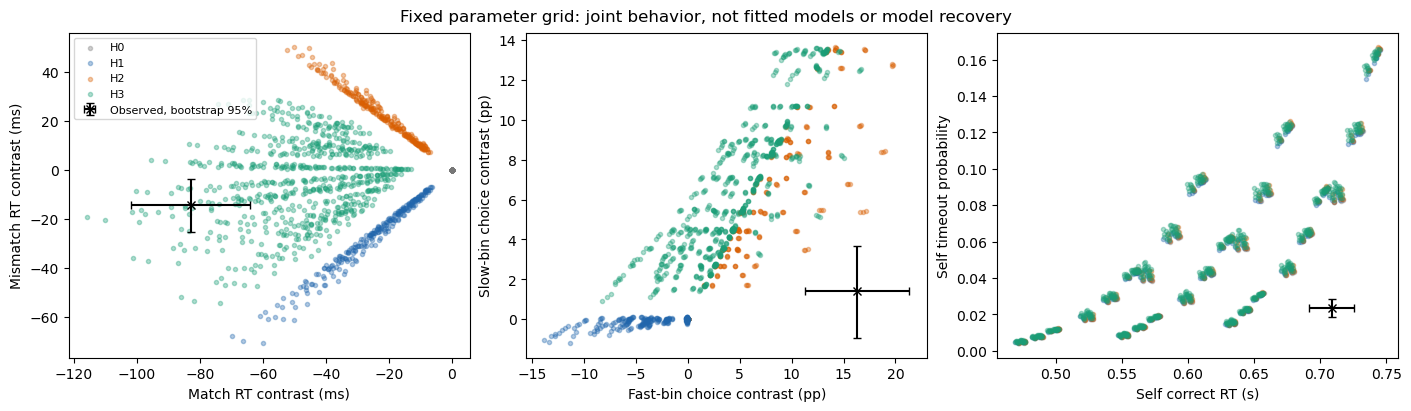

In [5]:
features=['delta_rt_match','delta_rt_mismatch','delta_acc_match','delta_acc_mismatch','timeout_self','delta_B1','delta_B3']
inside=pd.DataFrame({m:pred[m].between(obs_ci.loc[m,'lo'],obs_ci.loc[m,'hi']) for m in features})
counts=inside.assign(model=pred.model).groupby('model').sum()
counts['all_seven']=inside.all(axis=1).groupby(pred.model).sum()
counts['n_grid']=pred.groupby('model').size()
display(counts)
for label,cols in [('RT_pair',features[:2]),('RT_choice_timeout',features[:5]),('CBF_endpoints',features[-2:])]:
    print(label,inside[cols].all(axis=1).groupby(pred.model).sum().to_dict())
deadline_checks=[]
for shift in [-1/60,0,1/60]:
    row=expected(A,T,Z,1.,BV,BD,deadline_offset=shift)
    deadline_checks.append(dict(shift_ms=shift*1000,**row))
display(pd.DataFrame(deadline_checks)[['shift_ms','timeout_self','delta_rt_match','delta_rt_mismatch','delta_B1','delta_B3']].round(6))

fig,axes=plt.subplots(1,3,figsize=(14,4),constrained_layout=True)
colors={'H0':'#777777','H1':'#2166ac','H2':'#d95f02','H3':'#1b9e77'}
plots=[('delta_rt_match','delta_rt_mismatch',1000,'Match RT contrast (ms)','Mismatch RT contrast (ms)'),
       ('delta_B1','delta_B3',100,'Fast-bin choice contrast (pp)','Slow-bin choice contrast (pp)'),
       ('rt_self','timeout_self',1,'Self correct RT (s)','Self timeout probability')]
for ax,(x,y,scale,xlabel,ylabel) in zip(axes,plots):
    for model in MODELS:
        q=pred[pred.model.eq(model)];ax.scatter(q[x]*scale,q[y]*scale,s=9,alpha=.35,c=colors[model],label=model,rasterized=True)
    ax.errorbar(obs_ci.loc[x,'observed']*scale,obs_ci.loc[y,'observed']*scale,
                xerr=np.array([[obs_ci.loc[x,'observed']-obs_ci.loc[x,'lo']],[obs_ci.loc[x,'hi']-obs_ci.loc[x,'observed']]])*scale,
                yerr=np.array([[obs_ci.loc[y,'observed']-obs_ci.loc[y,'lo']],[obs_ci.loc[y,'hi']-obs_ci.loc[y,'observed']]])*scale,
                fmt='kx',capsize=3,lw=1.5,label='Observed, bootstrap 95%')
    ax.set(xlabel=xlabel,ylabel=ylabel)
axes[0].legend(fontsize=8)
fig.suptitle('Fixed parameter grid: joint behavior, not fitted models or model recovery')
plt.show()


## 5. 分布细节与个体参数代入检查

对同时落入 RT、正确率、超时五项参照区间的网格点，再检查正确和错误 RT 分位数以及 CBF。另用历史被试参数均值代入，检验单纯群体均值代入是否造成失配；z 使用 logit 均值的逆变换，此检查不传播后验不确定性，不等于 PPC。

错误 RT 对比仅在两个条件均有错误响应的被试中定义，bootstrap 使用这些有效配对并在表中报告人数。稀少错误响应的分位数仍应谨慎解释。


In [6]:
# Follow-up checks of all grid points satisfying the first five descriptive intervals.
# This is a post-grid diagnostic, not a new fitted estimate or independent validation.
screen=inside[features[:5]].all(axis=1)
points=pred.loc[screen,['a','t','z','vmult','bv','bd']]
display(points)
checks=[]
for idx,pars in points.iterrows():
    checks.append(dict(point='grid_'+str(idx),**expected(*pars.to_numpy(),details=True)))
checks.append(dict(point='historical_subject_plugin',**expected(A,T,Z,1.,BV,BD,details=True,individual=True)))
detail_table=pd.DataFrame(checks).set_index('point').T
detail_table=detail_table.join(obs_ci[['observed','lo','hi','n_subjects']])
with pd.option_context('display.max_rows',40,'display.max_columns',8):display(detail_table.round(5))
print('With a 5% contaminant that always responds, anchor timeout lower bound:',
      .95*expected(A,T,Z,1.,BV,BD)['timeout_self'])
assert {k:hashlib.sha256(p.read_bytes()).hexdigest() for k,p in paths.items()}==hashes


,a,t,z,vmult,bv,bd
474,1.224207,0.3,0.500000,1.2,0.358023,0.600222
522,1.224207,0.3,0.568092,1.2,0.358023,0.600222


,grid_474,grid_522,historical_subject_plugin,observed,lo,hi,n_subjects
delta_acc_match,0.13155,0.10356,0.15386,0.10889,0.07524,0.14254,42
delta_rt_match,-0.06821,-0.06448,-0.04050,-0.08293,-0.10174,-0.06417,42
delta_pmatch_match,0.10105,0.07588,0.10438,0.09869,0.06596,0.13126,42
delta_timeout_match,-0.03539,-0.03070,-0.06213,-0.01238,-0.01968,-0.00540,42
delta_acc_mismatch,0.01470,0.01881,0.01395,-0.01048,-0.04603,0.02540,42
delta_rt_mismatch,-0.01068,-0.01129,-0.00367,-0.01454,-0.02543,-0.00358,42
delta_pmatch_mismatch,-0.01129,-0.01518,-0.00918,0.01496,-0.02013,0.04871,42
delta_timeout_mismatch,-0.00387,-0.00436,-0.00728,-0.00698,-0.01651,0.00254,42
delta_cq10_match,-0.01472,-0.01133,-0.00871,-0.05788,-0.07332,-0.04252,42
delta_cq50_match,-0.05815,-0.05084,-0.03704,-0.09009,-0.11104,-0.06938,42


With a 5% contaminant that always responds, anchor timeout lower bound: 0.06180710950894511


## 结论的边界

结构可识别性是参数到数据分布的映射是否唯一；这里自由关系难度中心存在一个精确等价方向。有限样本实际可识别性还取决于噪声、试次数、误差响应数量、层级先验和采样质量。参数恢复需要重新估计生成参数；模型恢复需要对各生成模型的数据拟合全部候选并评价误判。本 Notebook 的 Jacobian 与前向网格都不等同于这两项恢复。

任何后续恢复必须注明关系难度参照约束。在未解决观察模型及关键分布失配前，不用旧 HDDM 的无截止似然拟合新删失模拟数据并称为恢复；也不直接运行真实数据竞争拟合。即使固定网格没有符合全部指标的点，也只能排除本轮网格及共同参数假设，不能证明整个 DDM 家族不充分。

参考资料：
- Hu et al. (2020). [Good Me Bad Me](https://doi.org/10.1525/collabra.301)，原文及程序提供任务和历史估计背景。
- Pan et al. (2025). [dockerHDDM](https://doi.org/10.1177/25152459241298700)，计算环境、诊断与恢复流程。
- 邬思宇、潘万柯、胡传鹏（2026）. [使用 dockerHDDM 对决策偏差进行建模](https://chinaxiv.org/abs/202604.00323)，本轮核对本地 v1 原文第 3.3–3.4 节；不是关于本实验识别能力的验证。
- [原始实验程序](https://github.com/hcp4715/moralSelf_ddm/tree/master/2_confirm_study/Procedure/confirmStudy_proc)
- [首轮前向模拟](matching_mechanism_simulation.ipynb)、[方案](matching_model_design.md)。
